# ScoNet from scratch (Scoliosis1K silhouette PKLs)

This notebook rebuilds ScoNet in **plain PyTorch**. It does not import anything from OpenGait, so there are no repo paths or config parsing to break. Every model piece has its own cell and a tiny shape test.

## The big picture

```
silhouette sequence  [frames, 64, 64]
   -> cut 10px off each side, divide by 255          [frames, 64, 44]
   -> pick 30 random frames                          [30, 64, 44]
   -> ResNet9 on every frame separately              [30, 512, 16, 11]
   -> max over the 30 frames  (temporal pooling)     [512, 16, 11]
   -> split into 16 horizontal strips (HPP)          [512, 16]
   -> one small FC per strip                         [256, 16]   <- "embedding" (used by triplet loss)
   -> BatchNorm + one cosine classifier per strip    [3, 16]     <- "logits"    (used by cross-entropy)
```

## The plan

| Part | What you do | Why |
|---|---|---|
| 1 | Settings | one place for every knob |
| 2 | Look at the data | see what a silhouette sequence is |
| 3 | Preprocessing | same crop and normalisation as `BaseSilCuttingTransform` |
| 4 | Model, piece by piece | each piece tested on its own |
| 5 | Losses | triplet + scaled cross-entropy, as in your YAML |
| 6 | Training loop | SGD, MultiStepLR, exactly the config values |
| 7 | **Sanity check** | 1 sample per class, the model must memorise it |
| 8 | Scale up (optional) | partition JSON, TripletSampler-style batches, evaluation |

Differences from official OpenGait (kept out on purpose to stay readable): no mixed precision (`enable_float16`), no multi-GPU or `sync_BN`, no checkpoint-restore logic.

## 1. Settings
Edit `DATASET_ROOT` so it points at the folder that **directly contains** the subject folders (`00000`, `00001`, ...).

In [1]:
import json, pickle, random
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

# ---- EDIT THIS ----
DATASET_ROOT = Path(r"C:\Users\arina\OneDrive\Documents\Reproduce_Paper\OpenGait\datasets\Scoliosis1K-sil-pkl\Scoliosis1K-sil-pkl")
# On Windows you can write: Path(r"C:\Users\you\...\Scoliosis1K-sil-pkl")

# ---- values taken from your YAML ----
LABELS = ["negative", "neutral", "positive"]      # class id = position in this list
LABEL_TO_ID = {name: i for i, name in enumerate(LABELS)}
N_FRAMES = 30          # trainer_cfg.sampler.frames_num_fixed
NUM_PARTS = 16         # bin_num
NUM_CLASSES = 3
CE_SCALE = 16          # CrossEntropyLoss scale
TRIPLET_MARGIN = 0.2

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if not DATASET_ROOT.is_dir():
    raise FileNotFoundError(
        f"DATASET_ROOT not found: {DATASET_ROOT.resolve()}\n"
        f"Current working folder: {Path.cwd()}\n"
        "Edit DATASET_ROOT above so it points at the folder that contains the subject folders."
    )
print("Device :", DEVICE, "| PyTorch", torch.__version__)
print("Dataset:", DATASET_ROOT.resolve())

Device : cuda | PyTorch 2.6.0+cu124
Dataset: C:\Users\arina\OneDrive\Documents\Reproduce_Paper\OpenGait\datasets\Scoliosis1K-sil-pkl\Scoliosis1K-sil-pkl


## 2. Look at the data

Expected layout: `<subject>/<class folder>/<view>/<file>.pkl`, where the class folder is Negative / Neutral / Positive. Each pkl is one silhouette video: a uint8 array `[frames, 64, 64]` with values 0 to 255.

The next cell grabs the first pkl of each class.

In [2]:
def find_one_sample_per_class(root):
    """Return {class_name: path_to_pkl} using the first pkl found for each class."""
    found = {}
    for pkl in root.rglob("*.pkl"):
        for folder in pkl.relative_to(root).parts[:-1]:
            name = folder.lower()
            if name in LABEL_TO_ID and name not in found:
                found[name] = pkl
        if len(found) == len(LABELS):
            break
    return found

def load_pkl(path):
    """Load one silhouette sequence as a uint8 array [T, H, W]."""
    with open(path, "rb") as f:
        seq = np.asarray(pickle.load(f))
    if seq.ndim == 4 and seq.shape[1] == 1:       # [T,1,H,W] -> [T,H,W]
        seq = seq[:, 0]
    elif seq.ndim == 4 and seq.shape[-1] == 1:    # [T,H,W,1] -> [T,H,W]
        seq = seq[..., 0]
    if seq.ndim != 3 or len(seq) == 0:
        raise ValueError(f"Expected a non-empty [T,H,W] array, got {seq.shape} from {path}")
    return seq

sample_paths = find_one_sample_per_class(DATASET_ROOT)
missing = [name for name in LABELS if name not in sample_paths]
if missing:
    raise FileNotFoundError(f"No pkl found for class(es) {missing} under {DATASET_ROOT}")

raw = {}    # class name -> uint8 array [T, H, W]
for name in LABELS:
    raw[name] = load_pkl(sample_paths[name])
    seq = raw[name]
    print(f"{name:9s} {str(sample_paths[name].relative_to(DATASET_ROOT)):45s} "
          f"shape={seq.shape} dtype={seq.dtype} range={seq.min()}..{seq.max()}")

negative  00493\negative\000_180\000_180.pkl            shape=(300, 64, 64) dtype=uint8 range=0..255
neutral   01293\neutral\000_180\000_180.pkl             shape=(300, 64, 64) dtype=uint8 range=0..255
positive  00000\positive\000_180\000_180.pkl            shape=(300, 64, 64) dtype=uint8 range=0..255


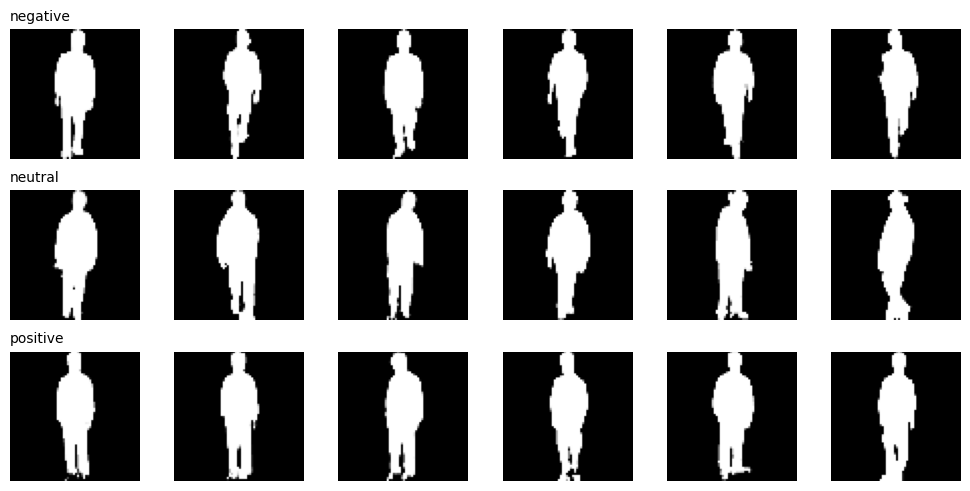

In [3]:
# A quick look: 6 evenly spaced frames from each sample
fig, axes = plt.subplots(len(LABELS), 6, figsize=(10, 5))
for row, name in enumerate(LABELS):
    seq = raw[name]
    for col, t in enumerate(np.linspace(0, len(seq) - 1, 6).round().astype(int)):
        axes[row, col].imshow(seq[t], cmap="gray")
        axes[row, col].axis("off")
    axes[row, 0].set_title(name, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

## 3. Preprocessing

Two tiny functions:

- `cut_and_normalize` copies `BaseSilCuttingTransform`: a 64 px wide image loses 10 px on each side (so 64 to 44 wide), then values are divided by 255.
- `random_clip` picks `N_FRAMES` random frames from a sequence. Training uses this (`fixed_unordered` in your YAML). Frame order does not matter because temporal pooling is a max.

In [4]:
def cut_and_normalize(seq):
    """uint8 [T, H, W]  ->  float32 [T, H, W-20] in 0..1  (same as BaseSilCuttingTransform)."""
    cut = seq.shape[-1] // 64 * 10
    if cut > 0:
        seq = seq[..., cut:-cut]
    return seq.astype(np.float32) / 255.0

def random_clip(seq, n_frames=N_FRAMES):
    """Pick n_frames random frames (with repeats only if the video is shorter)."""
    idx = np.random.choice(len(seq), n_frames, replace=len(seq) < n_frames)
    return seq[idx]

def train_clip(seq, n_frames=N_FRAMES):
    return cut_and_normalize(random_clip(seq, n_frames))

clip = cut_and_normalize(random_clip(raw["positive"]))
print("clip shape:", clip.shape, "| range:", clip.min(), "to", clip.max())
assert clip.shape == (N_FRAMES, 64, 44)

clip shape: (30, 64, 44) | range: 0.0 to 1.0


## 4. The model, one piece at a time

Naming used in the shape comments: `n` = batch (sequences), `s` = frames, `c` = channels, `h, w` = image size, `p` = parts (16).

### 4.1 Backbone: ResNet9
Four stages, one `BasicBlock` each (channels 64, 128, 256, 512 and strides 1, 2, 2, 1, no max-pool). A 64x44 image becomes a 512-channel 16x11 feature map.

In [5]:
class BasicBlock(nn.Module):
    """conv-bn-relu-conv-bn, plus a skip connection."""
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.relu = nn.ReLU(inplace=True)
        self.downsample = None
        if stride != 1 or in_ch != out_ch:        # skip path must match the new shape
            self.downsample = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 1, stride, bias=False), nn.BatchNorm2d(out_ch))

    def forward(self, x):
        identity = x if self.downsample is None else self.downsample(x)
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return self.relu(out + identity)

class ResNet9(nn.Module):
    def __init__(self, in_channels=1, channels=(64, 128, 256, 512), strides=(1, 2, 2, 1)):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(in_channels, channels[0], 3, 1, 1, bias=False),
            nn.BatchNorm2d(channels[0]), nn.ReLU(inplace=True))
        blocks, prev = [], channels[0]
        for ch, stride in zip(channels, strides):
            blocks.append(BasicBlock(prev, ch, stride))
            prev = ch
        self.blocks = nn.Sequential(*blocks)

    def forward(self, x):              # [n, 1, h, w] -> [n, 512, h/4, w/4]
        return self.blocks(self.stem(x))

# test: 5 images of 64x44
print(ResNet9()(torch.randn(5, 1, 64, 44)).shape)   # expect [5, 512, 16, 11]

torch.Size([5, 512, 16, 11])


### 4.2 Run the backbone on every frame
ResNet9 expects ordinary images `[batch, 1, h, w]`, but we have videos `[n, 1, s, h, w]`. `FrameWise` folds the frames into the batch dimension, runs the backbone, and unfolds again.

In [6]:
class FrameWise(nn.Module):
    def __init__(self, net):
        super().__init__()
        self.net = net

    def forward(self, x):                                   # x: [n, c, s, h, w]
        n, c, s, h, w = x.shape
        x = x.permute(0, 2, 1, 3, 4).reshape(n * s, c, h, w)    # every frame becomes its own image
        out = self.net(x)                                       # [n*s, c', h', w']
        _, c2, h2, w2 = out.shape
        return out.reshape(n, s, c2, h2, w2).permute(0, 2, 1, 3, 4)   # [n, c', s, h', w']

test = FrameWise(ResNet9())(torch.randn(2, 1, 7, 64, 44))
print(test.shape)   # expect [2, 512, 7, 16, 11]

torch.Size([2, 512, 7, 16, 11])


### 4.3 Horizontal pooling (HPP)
After the temporal max we have `[n, 512, 16, 11]`. HPP cuts the image into 16 horizontal strips (here exactly one row each) and summarises each strip as `mean + max`. Each strip then has its own classifier, so different body regions (shoulders, waist, ...) can specialise.

In [7]:
class HorizontalPooling(nn.Module):
    def __init__(self, num_parts=16):
        super().__init__()
        self.num_parts = num_parts

    def forward(self, x):                                   # x: [n, c, h, w]
        n, c = x.shape[:2]
        x = x.reshape(n, c, self.num_parts, -1)             # [n, c, p, strip_pixels]
        return x.mean(-1) + x.max(-1)[0]                    # [n, c, p]

print(HorizontalPooling(16)(torch.randn(2, 512, 16, 11)).shape)   # expect [2, 512, 16]

torch.Size([2, 512, 16])


### 4.4 SeparateFCs and SeparateBNNecks
"Separate" means each of the 16 parts has its **own** weights, stored as a `[parts, in, out]` tensor and applied with one batched matrix multiply.

- `SeparateFCs`: 512 to 256 per part. Its output is the **embedding** (triplet loss).
- `SeparateBNNecks`: BatchNorm, then a cosine classifier per part (256 to 3). Its output is the **logits** (cross-entropy). Features and class weights are L2-normalised, so each logit is a cosine similarity in [-1, 1], which is why the CE loss multiplies by a scale of 16.

In [8]:
class SeparateFCs(nn.Module):
    def __init__(self, parts, in_ch, out_ch):
        super().__init__()
        self.weight = nn.Parameter(nn.init.xavier_uniform_(torch.empty(parts, in_ch, out_ch)))

    def forward(self, x):                                   # x: [n, c, p]
        x = x.permute(2, 0, 1)                              # [p, n, c]
        return x.matmul(self.weight).permute(1, 2, 0)       # [p, n, out] -> [n, out, p]

class SeparateBNNecks(nn.Module):
    def __init__(self, parts, in_ch, num_classes):
        super().__init__()
        self.bn = nn.BatchNorm1d(in_ch * parts)
        self.weight = nn.Parameter(nn.init.xavier_uniform_(torch.empty(parts, in_ch, num_classes)))

    def forward(self, x):                                   # x: [n, c, p]
        n, c, p = x.shape
        x = self.bn(x.reshape(n, c * p)).reshape(n, c, p)
        feat = F.normalize(x.permute(2, 0, 1), dim=-1)      # [p, n, c], unit length
        w = F.normalize(self.weight, dim=1)                 # [p, c, classes], unit length per class
        logits = feat.matmul(w)                             # [p, n, classes]  (cosine similarity)
        return x, logits.permute(1, 2, 0)                   # features [n, c, p], logits [n, classes, p]

e = SeparateFCs(16, 512, 256)(torch.randn(4, 512, 16))
f, l = SeparateBNNecks(16, 256, 3)(e)
print(e.shape, f.shape, l.shape)    # expect [4,256,16] [4,256,16] [4,3,16]

torch.Size([4, 256, 16]) torch.Size([4, 256, 16]) torch.Size([4, 3, 16])


### 4.5 Put it together: ScoNet

In [9]:
class ScoNet(nn.Module):
    def __init__(self, num_parts=NUM_PARTS, num_classes=NUM_CLASSES):
        super().__init__()
        self.backbone = FrameWise(ResNet9())
        self.hpp = HorizontalPooling(num_parts)
        self.fcs = SeparateFCs(num_parts, 512, 256)
        self.bnnecks = SeparateBNNecks(num_parts, 256, num_classes)

    def forward(self, sils):                 # sils: [n, s, h, w]  (silhouettes, 0..1)
        x = sils.unsqueeze(1)                # [n, 1, s, h, w]  add the channel dimension
        x = self.backbone(x)                 # [n, 512, s, 16, 11]
        x = x.max(dim=2)[0]                  # [n, 512, 16, 11]  temporal pooling: max over frames
        x = self.hpp(x)                      # [n, 512, 16]
        embed = self.fcs(x)                  # [n, 256, 16]
        _, logits = self.bnnecks(embed)      # [n, 3, 16]
        return embed, logits

def init_weights(m):
    """Same initialisation idea as OpenGait's init_parameters."""
    if isinstance(m, nn.Conv2d):
        nn.init.xavier_uniform_(m.weight)
    elif isinstance(m, (nn.BatchNorm1d, nn.BatchNorm2d)) and m.affine:
        nn.init.normal_(m.weight, 1.0, 0.02)
        nn.init.zeros_(m.bias)

def make_model():
    model = ScoNet()
    model.apply(init_weights)
    return model.to(DEVICE)

model = make_model()
print(f"Parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f}M")

with torch.no_grad():
    embed, logits = model.eval()(torch.rand(2, N_FRAMES, 64, 44, device=DEVICE))
print("embed :", tuple(embed.shape), " expect (2, 256, 16)")
print("logits:", tuple(logits.shape), " expect (2, 3, 16)")
assert embed.shape == (2, 256, 16) and logits.shape == (2, 3, 16)

Parameters: 7.01M
embed : (2, 256, 16)  expect (2, 256, 16)
logits: (2, 3, 16)  expect (2, 3, 16)


## 5. Losses

Total loss = `triplet + cross-entropy` (both weight 1.0 in your YAML).

- **Triplet loss** works on the 256-d embeddings. It pulls clips with the **same subject id** together and pushes different ids apart by at least `margin = 0.2`. Same convention as your ScoNet file (`'labels': pids`). It needs at least two clips per id in the batch, which is what the TripletSampler guarantees.
- **Cross-entropy** works on the logits and uses the class (negative / neutral / positive). Every one of the 16 parts has to predict the right class.

In [ ]:
def triplet_loss(embed, ids, margin=TRIPLET_MARGIN):
    """embed: [n, c, p]   ids: [n] subject ids.  Returns a scalar."""
    e = embed.permute(2, 0, 1)                                    # [p, n, c]
    sq = (e ** 2).sum(-1)                                         # [p, n]
    d2 = sq.unsqueeze(2) + sq.unsqueeze(1) - 2 * e.matmul(e.transpose(1, 2))
    dist = torch.sqrt(F.relu(d2) + 1e-12)                         # [p, n, n] pairwise distances

    same = ids.unsqueeze(0) == ids.unsqueeze(1)                   # [n, n] same subject?
    eye = torch.eye(len(ids), dtype=torch.bool, device=ids.device)
    pos_mask = same & ~eye                                        # anchor-positive pairs
    neg_mask = ~same                                              # anchor-negative pairs
    valid = pos_mask.unsqueeze(2) & neg_mask.unsqueeze(1)         # [anchor, pos, neg]
    if not valid.any():                                           # no triplets possible in this batch
        return embed.sum() * 0.0

    # loss for every (anchor, positive, negative) triple: max(0, d(a,p) - d(a,n) + margin)
    loss = F.relu(dist.unsqueeze(3) - dist.unsqueeze(2) + margin)  # [p, anchor, pos, neg]
    loss = loss[:, valid]                                          # [p, num_valid_triplets]
    nonzero = (loss > 0).sum(1).clamp(min=1)
    return (loss.sum(1) / nonzero).mean()                          # average only the active triplets

def scaled_ce_loss(logits, classes, scale=CE_SCALE):
    """logits: [n, k, p]   classes: [n].  Cross-entropy for every part, averaged."""
    n, k, p = logits.shape
    target = classes.unsqueeze(1).expand(n, p)                    
    return F.cross_entropy(logits * scale, target)

# test with random data: 2 subjects x 3 clips each
t = triplet_loss(torch.randn(6, 256, 16), torch.tensor([0, 0, 0, 1, 1, 1]))
c = scaled_ce_loss(torch.randn(6, 3, 16), torch.tensor([0, 0, 0, 1, 1, 2]))
print("triplet:", float(t), "| ce:", float(c))

triplet: 1.0707191228866577 | ce: 11.729720115661621


## 6. Training loop

One iteration: get a batch, forward, compute both losses, backward, SGD step. Optimizer settings come from your YAML: SGD, lr 0.1, momentum 0.9, weight decay 5e-4, learning rate multiplied by 0.1 at each milestone.

`get_batch()` can be any function that returns `(silhouettes [n,s,h,w], subject_ids [n], class_ids [n])`. The sanity check and the full run below just plug in different batch functions.

In [11]:
def train(model, get_batch, iters, lr=0.1, milestones=(), log_every=10):
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=5e-4)
    scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=list(milestones), gamma=0.1)
    history = {"triplet": [], "ce": [], "acc": []}

    for it in range(1, iters + 1):
        model.train()
        sils, ids, classes = get_batch()
        sils = torch.as_tensor(sils, dtype=torch.float32, device=DEVICE)
        ids = torch.as_tensor(ids, dtype=torch.long, device=DEVICE)
        classes = torch.as_tensor(classes, dtype=torch.long, device=DEVICE)

        embed, logits = model(sils)
        loss_tri = triplet_loss(embed, ids)
        loss_ce = scaled_ce_loss(logits, classes)
        loss = loss_tri + loss_ce

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scheduler.step()

        acc = (logits.mean(-1).argmax(1) == classes).float().mean().item()   # average the 16 parts, then argmax
        history["triplet"].append(loss_tri.item())
        history["ce"].append(loss_ce.item())
        history["acc"].append(acc)
        if it == 1 or it % log_every == 0:
            print(f"iter {it:5d} | triplet {loss_tri.item():.4f} | ce {loss_ce.item():.4f} | acc {acc:.2f}")
    return history

def plot_history(history):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    ax[0].plot(history["triplet"], label="triplet"); ax[0].plot(history["ce"], label="cross-entropy")
    ax[0].set_xlabel("iteration"); ax[0].set_title("loss"); ax[0].legend()
    ax[1].plot(history["acc"]); ax[1].set_xlabel("iteration"); ax[1].set_title("train accuracy"); ax[1].set_ylim(0, 1.05)
    plt.tight_layout(); plt.show()

For evaluation we use the **whole** sequence (up to 720 frames, like `frames_all_limit` in your YAML). The model returns logits `[1, 3, 16]`; averaging over the 16 parts gives one score per class, and the biggest score is the prediction.

In [12]:
@torch.no_grad()
def predict(model, seq_uint8, max_frames=720):
    """One raw sequence [T, 64, 64] -> (predicted class id, class probabilities)."""
    model.eval()
    if len(seq_uint8) > max_frames:
        seq_uint8 = seq_uint8[np.linspace(0, len(seq_uint8) - 1, max_frames).round().astype(int)]
    x = torch.from_numpy(cut_and_normalize(seq_uint8)).unsqueeze(0).to(DEVICE)    # [1, T, 64, 44]
    _, logits = model(x)                                                           # [1, 3, 16]
    scores = logits.mean(-1)                                                       # [1, 3]
    probs = torch.softmax(scores * CE_SCALE, dim=-1)[0].cpu().numpy()
    return int(probs.argmax()), probs

## 7. Sanity check: 1 sample per class

**Goal:** show the code works end to end. With only three videos the model must be able to memorise them. If it cannot, something is broken.

**Trick:** the triplet loss needs several clips per subject. We have only one video per class, so each batch cuts **K different random 30-frame clips** out of every video and treats the clips of one video as the same "subject". With 3 videos and K clips each, a batch has 3K sequences.

If you hit an out-of-memory error, lower `K_CLIPS` or `SANITY_FRAMES`. On CPU the notebook automatically uses a smaller setup so it finishes.

In [13]:
if DEVICE.type == "cuda":
    SANITY_FRAMES, K_CLIPS, SANITY_ITERS, EVAL_MAX_FRAMES = N_FRAMES, 4, 100, 720
else:                                   # CPU: smaller and slower-to-fail setup
    SANITY_FRAMES, K_CLIPS, SANITY_ITERS, EVAL_MAX_FRAMES = 8, 2, 60, 100
SANITY_LR = 0.1                         # lower to 0.01 if the loss jumps around

def get_sanity_batch():
    clips, ids, classes = [], [], []
    for class_id, name in enumerate(LABELS):
        for _ in range(K_CLIPS):
            clips.append(train_clip(raw[name], SANITY_FRAMES))
            ids.append(class_id)          # one video per class -> its id is just the class number
            classes.append(class_id)
    return np.stack(clips), np.array(ids), np.array(classes)

sils, ids, classes = get_sanity_batch()
print("batch silhouettes:", sils.shape, "| ids:", ids, "| classes:", classes)

batch silhouettes: (12, 30, 64, 44) | ids: [0 0 0 0 1 1 1 1 2 2 2 2] | classes: [0 0 0 0 1 1 1 1 2 2 2 2]


iter     1 | triplet 0.1246 | ce 1.4367 | acc 0.25
iter    10 | triplet 0.4688 | ce 0.1395 | acc 1.00
iter    20 | triplet 0.4537 | ce 0.0070 | acc 1.00
iter    30 | triplet 0.4092 | ce 0.0254 | acc 1.00
iter    40 | triplet 0.2849 | ce 0.0339 | acc 1.00
iter    50 | triplet 0.0000 | ce 0.0012 | acc 1.00
iter    60 | triplet 0.1308 | ce 0.0003 | acc 1.00
iter    70 | triplet 0.1257 | ce 0.0017 | acc 1.00
iter    80 | triplet 0.0347 | ce 0.0006 | acc 1.00
iter    90 | triplet 0.1386 | ce 0.0004 | acc 1.00
iter   100 | triplet 0.0000 | ce 0.0001 | acc 1.00


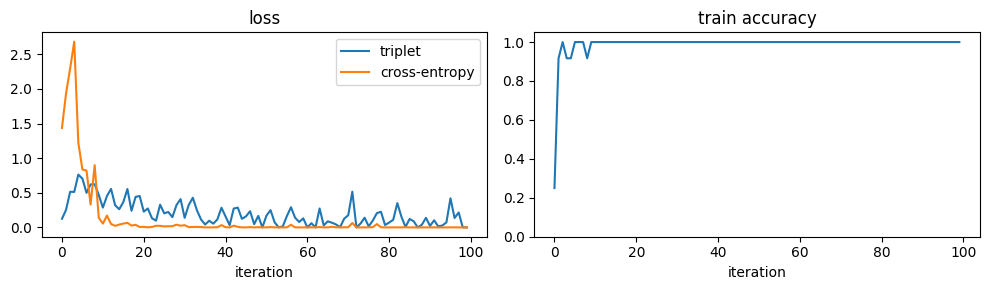

In [14]:
sanity_model = make_model()
history = train(sanity_model, get_sanity_batch, iters=SANITY_ITERS, lr=SANITY_LR, log_every=10)
plot_history(history)

In [15]:
ce_start, ce_end = np.mean(history["ce"][:3]), np.mean(history["ce"][-5:])
acc_end = np.mean(history["acc"][-5:])
print(f"cross-entropy: {ce_start:.3f} -> {ce_end:.3f}")
print(f"train accuracy (last 5 iters): {acc_end:.2f}")
print("TRAINING CHECK:", "PASS" if (ce_end < 0.5 * ce_start and acc_end >= 0.99) else "FAIL - see notes below")

cross-entropy: 1.890 -> 0.000
train accuracy (last 5 iters): 1.00
TRAINING CHECK: PASS


Now the evaluation path: whole video in, prediction out. The same three videos are used, so this only proves the eval code works.

In [16]:
correct = 0
for class_id, name in enumerate(LABELS):
    pred, probs = predict(sanity_model, raw[name], EVAL_MAX_FRAMES)
    correct += int(pred == class_id)
    print(f"true {name:9s} -> predicted {LABELS[pred]:9s} probs (neg, neu, pos) = {np.round(probs, 3)}")
print(f"\nEVAL CHECK: {correct}/3 correct")

true negative  -> predicted negative  probs (neg, neu, pos) = [0.999 0.    0.001]
true neutral   -> predicted negative  probs (neg, neu, pos) = [0.976 0.002 0.022]
true positive  -> predicted positive  probs (neg, neu, pos) = [0.107 0.    0.893]

EVAL CHECK: 2/3 correct


### How to read the result

| What you see | Meaning |
|---|---|
| Training CHECK = PASS and eval 3/3 | The whole pipeline works. |
| Training PASS but eval is wrong | Usually the train/test mismatch: training saw 30-frame clips, eval sees the whole video, so the temporal max and the BatchNorm statistics differ. Try `EVAL_MAX_FRAMES = N_FRAMES` in the sanity cell. With real training on many subjects this gap largely disappears. |
| Training FAIL, loss stays flat or becomes `nan` | Try `SANITY_LR = 0.01`. If it is still flat, check that the data cell printed sensible shapes and a 0..255 range, and that the three samples really come from different classes. |
| Shape errors | Compare against the shape comments in Part 4, they match what each test cell prints. |

## 8. Scale up (optional): train on a subset or the full dataset

Same model, same `train()`. Only the batch function changes.

- The partition JSON (`TRAIN_SET` / `TEST_SET` lists of subject ids) decides who trains and who tests. Subject folders listed in the JSON but missing on disk are skipped, so this also works with a downloaded **subset**.
- `make_triplet_batch_fn` copies the TripletSampler idea: pick `IDS_PER_BATCH` subjects, then `SEQS_PER_ID` sequences each.
- Your YAML uses 8 x 8 for 20000 iterations. The defaults below are smaller so a first run finishes quickly.

Set `RUN_FULL = True` when you are ready.

In [21]:
repo = Path.cwd().parent          # OpenGait folder (the notebook runs from OpenGait\notebooks)
print(list(repo.rglob("Scoliosis1K_118.json")))

[WindowsPath('c:/Users/arina/OneDrive/Documents/Reproduce_Paper/OpenGait/datasets/Scoliosis1K/Scoliosis1K_118.json')]


In [23]:
RUN_FULL = True
PARTITION_JSON = Path(r"c:/Users/arina/OneDrive/Documents/Reproduce_Paper/OpenGait/datasets/Scoliosis1K/Scoliosis1K_118.json")   # EDIT if yours lives elsewhere
TOTAL_ITERS = 200            # YAML: 20000
IDS_PER_BATCH = 4            # YAML: 8
SEQS_PER_ID = 4              # YAML: 8
FULL_EVAL_FRAMES = 720       # YAML: frames_all_limit

_cache = {}
def load_pkl_cached(path):
    if path not in _cache:
        _cache[path] = load_pkl(path)
    return _cache[path]

def build_index(root, subject_ids):
    """List (subject_id, class_id, pkl_path) for every sequence of the given subjects."""
    items, missing = [], 0
    for sid in subject_ids:
        folder = root / str(sid)
        if not folder.is_dir():
            missing += 1
            continue
        for pkl in sorted(folder.rglob("*.pkl")):
            names = [p.lower() for p in pkl.relative_to(root).parts[:-1]]
            class_id = next((LABEL_TO_ID[n] for n in names if n in LABEL_TO_ID), None)
            if class_id is not None:
                items.append((str(sid), class_id, pkl))
    print(f"{len(items)} sequences from {len(set(i[0] for i in items))} subjects ({missing} listed subjects not on disk)")
    return items

def make_triplet_batch_fn(items, ids_per_batch, seqs_per_id):
    by_subject = {}
    for sid, class_id, path in items:
        by_subject.setdefault(sid, []).append((class_id, path))
    subjects = list(by_subject)
    index = {sid: i for i, sid in enumerate(subjects)}

    def get_batch():
        clips, ids, classes = [], [], []
        for sid in random.sample(subjects, min(ids_per_batch, len(subjects))):
            pool = by_subject[sid]
            picks = random.sample(pool, seqs_per_id) if len(pool) >= seqs_per_id else random.choices(pool, k=seqs_per_id)
            for class_id, path in picks:
                clips.append(train_clip(load_pkl_cached(path)))
                ids.append(index[sid])
                classes.append(class_id)
        return np.stack(clips), np.array(ids), np.array(classes)
    return get_batch

def evaluate(model, items, max_frames=FULL_EVAL_FRAMES):
    """Confusion matrix + accuracy, per-class precision / recall / F1."""
    conf = np.zeros((3, 3), dtype=int)                     # rows = true, columns = predicted
    for _, class_id, path in items:
        pred, _ = predict(model, load_pkl_cached(path), max_frames)
        conf[class_id, pred] += 1
    print("confusion matrix (rows = true, cols = predicted):\n", conf)
    print(f"accuracy: {conf.trace() / max(conf.sum(), 1):.3f}")
    for k, name in enumerate(LABELS):
        recall = conf[k, k] / max(conf[k].sum(), 1)
        precision = conf[k, k] / max(conf[:, k].sum(), 1)
        f1 = 2 * precision * recall / max(precision + recall, 1e-9)
        print(f"  {name:9s} precision {precision:.3f}  recall {recall:.3f}  f1 {f1:.3f}")
    return conf

744 sequences from 744 subjects (0 listed subjects not on disk)
749 sequences from 749 subjects (0 listed subjects not on disk)
iter     1 | triplet 0.1238 | ce 1.3773 | acc 0.44
iter    20 | triplet 1.0635 | ce 1.3457 | acc 0.50
iter    40 | triplet 0.8708 | ce 1.3155 | acc 0.50
iter    60 | triplet 0.4098 | ce 0.8047 | acc 0.81
iter    80 | triplet 0.4520 | ce 0.9945 | acc 0.62
iter   100 | triplet 0.1881 | ce 0.9266 | acc 0.75
iter   120 | triplet 0.2794 | ce 0.3519 | acc 1.00
iter   140 | triplet 0.2872 | ce 0.3651 | acc 1.00
iter   160 | triplet 0.2951 | ce 1.0521 | acc 0.50
iter   180 | triplet 0.3159 | ce 0.3451 | acc 1.00
iter   200 | triplet 0.4876 | ce 1.1837 | acc 0.50


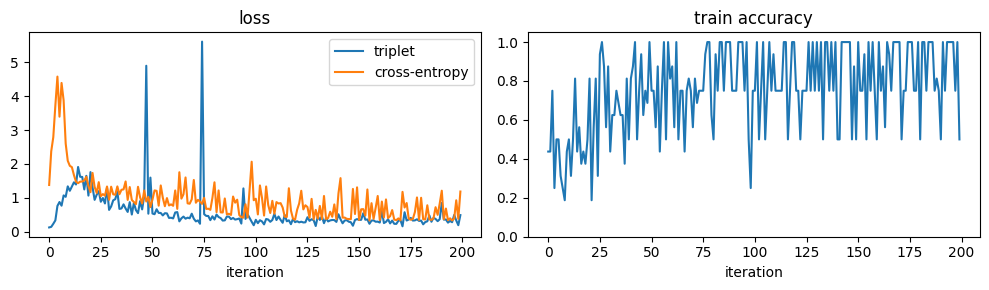


Evaluation on the TEST_SET:
confusion matrix (rows = true, cols = predicted):
 [[204   0   0]
 [126   0   0]
 [417   0   2]]
accuracy: 0.275
  negative  precision 0.273  recall 1.000  f1 0.429
  neutral   precision 0.000  recall 0.000  f1 0.000
  positive  precision 1.000  recall 0.005  f1 0.010


In [24]:
if not RUN_FULL:
    print("RUN_FULL is False -> skipping. Set it to True above to train on the partition.")
else:
    with open(PARTITION_JSON, "r", encoding="utf-8") as f:
        partition = json.load(f)
    train_items = build_index(DATASET_ROOT, partition["TRAIN_SET"])
    test_items = build_index(DATASET_ROOT, partition["TEST_SET"])

    full_model = make_model()
    get_batch = make_triplet_batch_fn(train_items, IDS_PER_BATCH, SEQS_PER_ID)
    milestones = [int(TOTAL_ITERS * f) for f in (0.5, 0.7, 0.9)]      # YAML: 10000 / 14000 / 18000 of 20000
    history_full = train(full_model, get_batch, iters=TOTAL_ITERS, lr=0.1, milestones=milestones, log_every=20)
    plot_history(history_full)

    torch.save(full_model.state_dict(), "sconet_scratch.pt")
    print("\nEvaluation on the TEST_SET:")
    evaluate(full_model, test_items)

## Where to go from here

1. Run Parts 1 to 7 until both checks pass.
2. Run Part 8 with the defaults on your subset and confirm the loss goes down.
3. Compare this model with the OpenGait version on the same inputs: load the same weights into both, feed the same tensor, check that the logits match. That is the real test that the reproduction is faithful.
4. Raise `TOTAL_ITERS`, `IDS_PER_BATCH` and `SEQS_PER_ID` toward the YAML values (20000, 8, 8) and report accuracy plus per-class precision, recall and F1.